In [2]:
# import things

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
def f1(y_true, y_pred):
    def recall_m(y_true, y_pred):
        TP = K.sum(K.round(K.clip(y_true * y_pred, 0, 1)))
        Positives = K.sum(K.round(K.clip(y_true, 0, 1)))
        recall = TP / (Positives+K.epsilon())
        return recall

    def precision_m(y_true, y_pred):
        TP = K.sum(K.round(K.clip(y_true * y_pred, 0, 1)))
        Pred_Positives = K.sum(K.round(K.clip(y_pred, 0, 1)))
        precision = TP / (Pred_Positives+K.epsilon())
        return precision

    precision, recall = precision_m(y_true, y_pred), recall_m(y_true, y_pred)

    return 2*((precision*recall)/(precision+recall+K.epsilon()))

In [9]:
from tensorflow.keras.models import load_model
from tensorflow.keras import backend as K
import tensorflow as tf

def dice_loss(y_true, y_pred):
    smooth = 1e-6
    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(y_pred)
    intersection = K.sum(y_true_f * y_pred_f)
    return 1 - (2. * intersection + smooth) / (
        K.sum(y_true_f) + K.sum(y_pred_f) + smooth)

def bce_dice_loss(y_true, y_pred):
    weight        = 1.0 + 2.0 * y_true
    bce_per_pixel = tf.keras.losses.binary_crossentropy(y_true, y_pred, axis=-1)
    weighted_bce  = tf.reduce_mean(weight[..., 0] * bce_per_pixel)
    return 0.5 * weighted_bce + 0.5 * dice_loss(y_true, y_pred)

patch_size = 256
example_file_name = f'/content/drive/MyDrive/Client_data/dataset_for_unet_patched/Mohammadali_244437_unet_model_256px.keras'

model = load_model(example_file_name, custom_objects={
    "f1": f1,
    "bce_dice_loss": bce_dice_loss,
    "dice_loss": dice_loss
})
print("Model loaded!")

Model loaded!


/usr/local/lib/python3.12/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'rmsprop', because it has 84 variables whereas the saved optimizer has 166 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [10]:
# Define any functions you need to process the mask e.g. Task 2
# Petri dish crop
def get_dish_bbox(img, black_threshold=80, padding=20):
    binary = (img > black_threshold).astype(np.uint8)
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (50, 50))
    binary = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)
    binary = cv2.morphologyEx(binary, cv2.MORPH_ERODE, kernel)
    contours, _ = cv2.findContours(binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    largest = max(contours, key=cv2.contourArea)
    x, y, w, h = cv2.boundingRect(largest)
    H, W = img.shape
    x1 = max(0, x - padding)
    y1 = max(0, y - padding)
    x2 = min(W, x + w + padding)
    y2 = min(H, y + h + padding)
    return x1, y1, x2, y2

def binarize_mask(msk):
    return (msk > 0).astype(np.float32)

In [12]:
# Load the test image
import cv2
task5_test_image_path = '/content/task5_test_image (1).png'
image = cv2.imread(task5_test_image_path, 0)
h, w = image.shape
print(h, w)

3006 4112


In [14]:
# Find the petri dish
# Find the petri dish
import numpy as np

x1, y1, x2, y2 = get_dish_bbox(image, black_threshold=80, padding=20)
petri_dish = image[y1:y2, x1:x2]
print("petri_dish.shape:", petri_dish.shape)
petri_dish.shape

petri_dish.shape: (2734, 2691)


(2734, 2691)

In [15]:
# Pad the petri dish
def pad_to_multiple(img, patch_size=256):
    h, w = img.shape
    new_h = int(np.ceil(h / patch_size) * patch_size)
    new_w = int(np.ceil(w / patch_size) * patch_size)
    padded = np.zeros((new_h, new_w), dtype=img.dtype)
    padded[:h, :w] = img
    return padded, h, w

petri_dish_padded, orig_h, orig_w = pad_to_multiple(petri_dish, patch_size)
print("petri_dish_padded.shape:", petri_dish_padded.shape)

petri_dish_padded.shape

petri_dish_padded.shape: (2816, 2816)


(2816, 2816)

Patches shape: (121, 256, 256)
4/4 ━━━━━━━━━━━━━━━━━━━━ 283s 69s/step


Text(0.5, 1.0, 'Prediction')

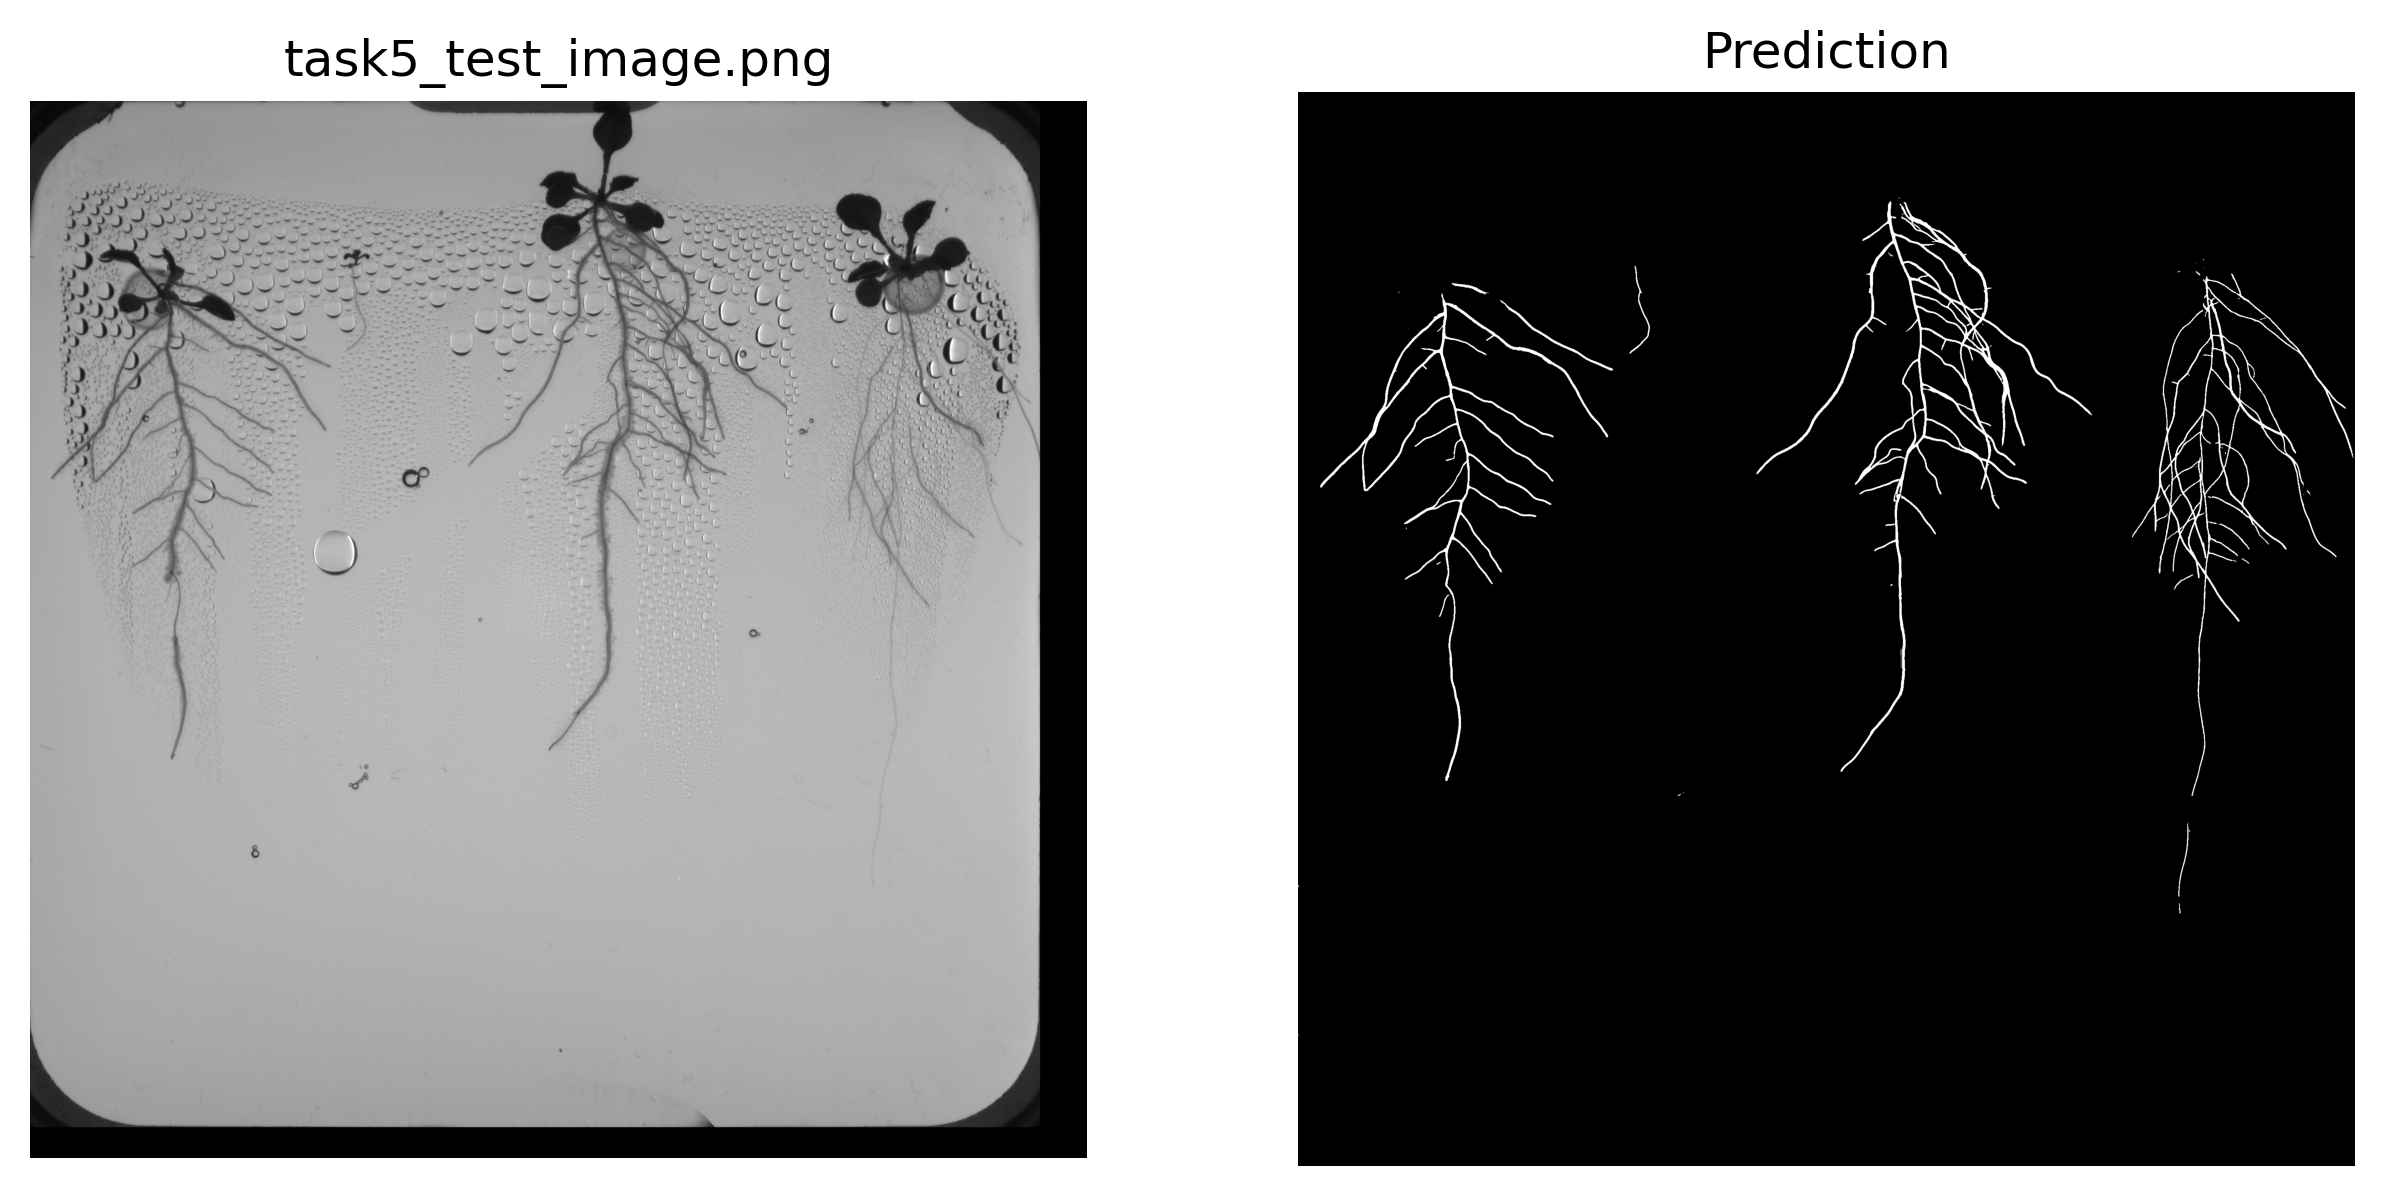

In [17]:
# PATCH
import matplotlib.pyplot as plt
def extract_patches(img, patch_size=256):
    H, W = img.shape
    patches = []
    for r in range(0, H, patch_size):
        for c in range(0, W, patch_size):
            patch = img[r:r+patch_size, c:c+patch_size]
            patches.append(patch)
    return np.array(patches, dtype=np.float32) / 255.0

patches = extract_patches(petri_dish_padded, patch_size)
print(f"Patches shape: {patches.shape}")

# PREDICT
patches_input = patches[..., np.newaxis]  # add channel dim
predictions = model.predict(patches_input, verbose=1)

# UNPATCH
def reconstruct_from_patches(predictions, padded_shape, patch_size=256):
    H, W = padded_shape
    full_mask = np.zeros((H, W), dtype=np.float32)
    idx = 0
    for r in range(0, H, patch_size):
        for c in range(0, W, patch_size):
            full_mask[r:r+patch_size, c:c+patch_size] = predictions[idx, :, :, 0]
            idx += 1
    return full_mask

predicted_mask_padded = reconstruct_from_patches(
    predictions, petri_dish_padded.shape, patch_size)

# Crop back to original petri dish size (remove padding)
predicted_mask = predicted_mask_padded[:orig_h, :orig_w]
predicted_mask = (predicted_mask > 0.5).astype(np.uint8) * 255


f, ax = plt.subplots(1, 2, dpi=300, figsize=(10, 5))
ax[0].imshow(petri_dish_padded, cmap='gray')
ax[0].axis('off')
ax[0].set_title('task5_test_image.png')
ax[1].imshow(predicted_mask, cmap='gray')
ax[1].axis('off')
ax[1].set_title('Prediction')

In [18]:
predicted_mask.shape, image.shape

((2734, 2691), (3006, 4112))

As you can see `predicted_mask` and `image` have different shapes. This is because of cropping and padding.

**REQUIREMENT:** The input and output should have the same size and should be aligned perfectly. To achieve this, you need to reverse the effects of cropping and padding added during processing. This will ensure the final mask aligns with the original image.

In [19]:
# Apply the corrections
predicted_mask_corrected = np.zeros((h, w), dtype=np.float32)
predicted_mask_corrected[y1:y2, x1:x2] = predicted_mask[:orig_h, :orig_w] / 255.0
predicted_mask_corrected = (predicted_mask_corrected > 0.5).astype(np.float32)

print("predicted_mask_corrected.shape:", predicted_mask_corrected.shape)
assert predicted_mask_corrected.shape == image.shape

predicted_mask_corrected.shape

predicted_mask_corrected.shape: (3006, 4112)


(3006, 4112)

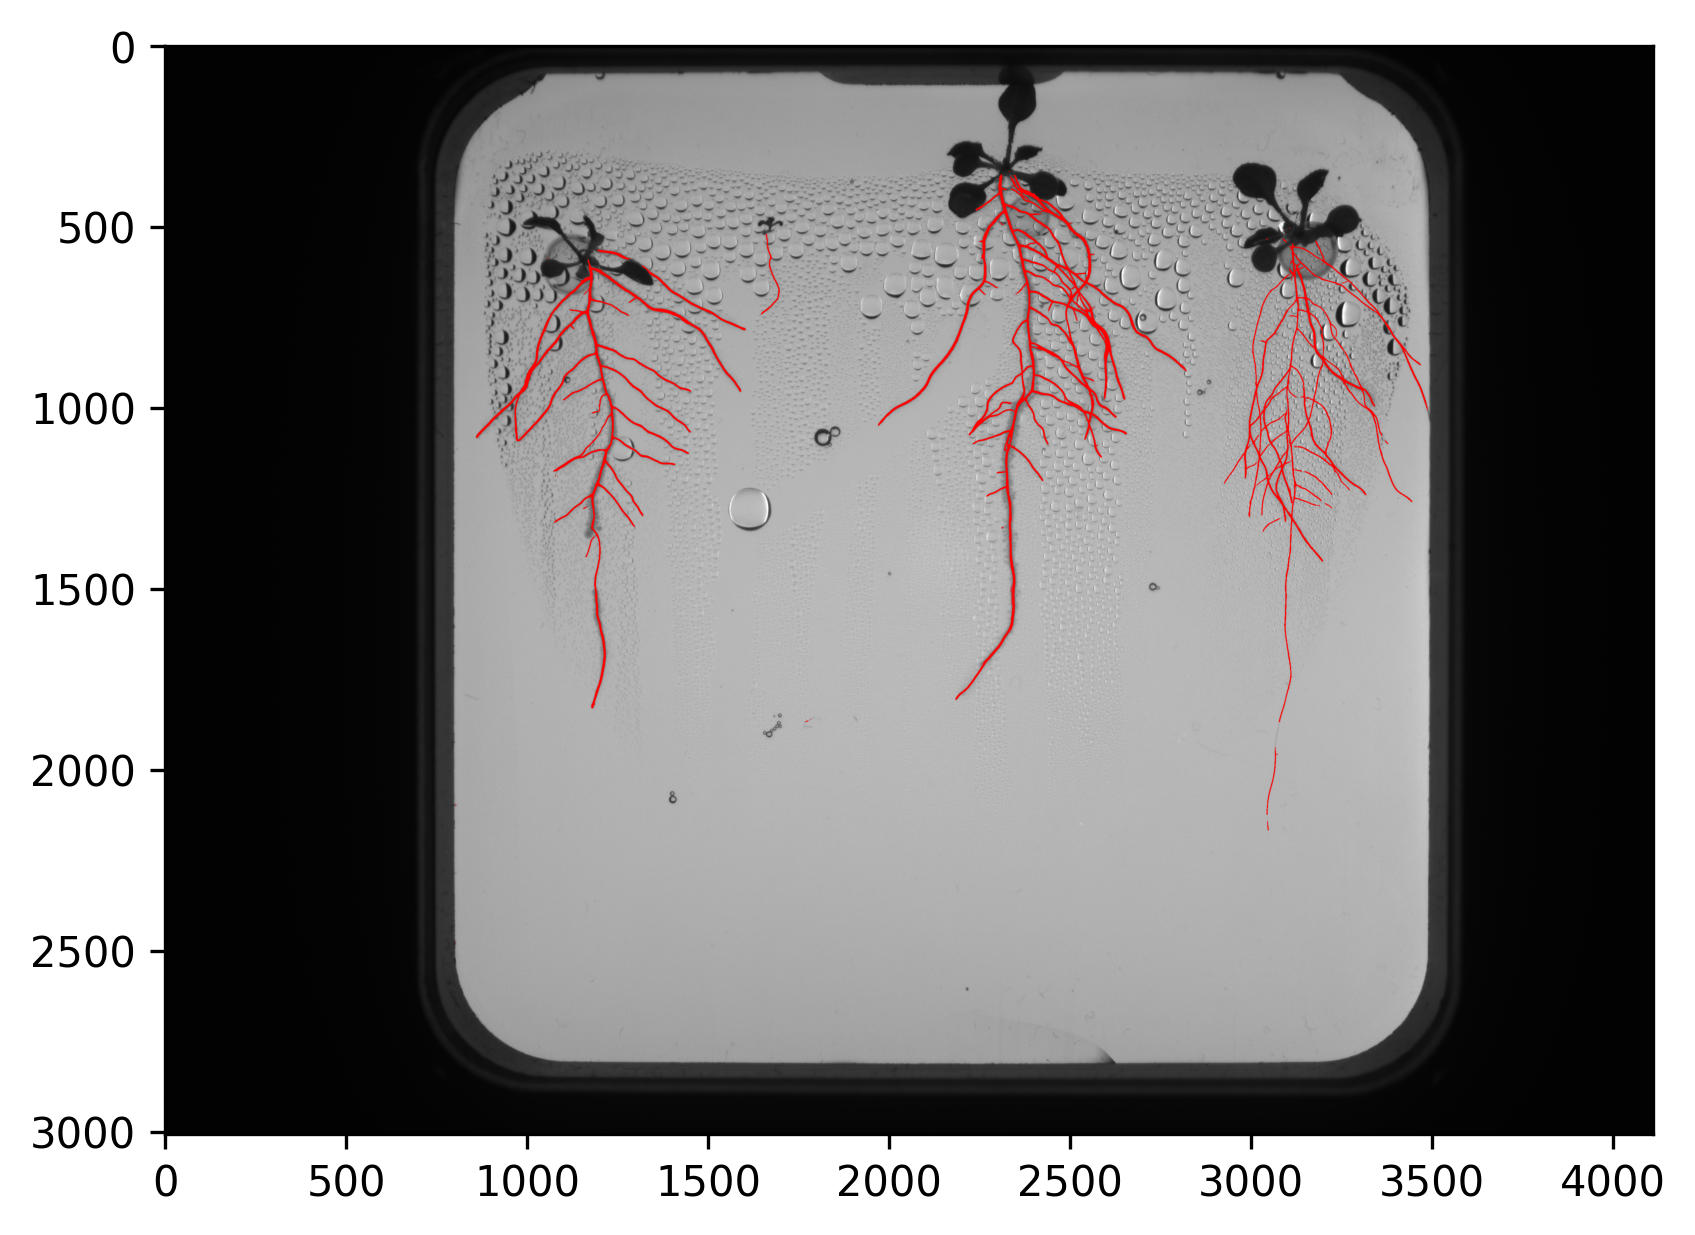

In [20]:
# REQUIREMENT: Predicted roots must align with the original image.
# REQUIREMENT: Plot such an image to prove alignment.
overlay_image = np.stack([image, image, image], axis=-1)  # grayscale to RGB
overlay_image[predicted_mask_corrected == 1] = [255, 0, 0]  # red for roots

plt.figure(dpi=300)
plt.imshow(overlay_image)

In [21]:
# REQUIREMENT: Save the predicted mask, it is a deliverable.
# REQUIREMENT: Input/Output size must be the same.
# REQUIREMENT: Predicted roots must align with the original image.
# REQUIREMENT: The predicted mask must be binary.
# REQUIREMENT: Non-root pixels must be 0, root pixels must be 255 (unlike Task 1)
# REQUIREMENT: naming convention task5_test_image_prediction_studentname_studentnumber.png
mask_image = (predicted_mask_corrected * 255).astype(np.uint8)
assert predicted_mask_corrected.shape == image.shape
cv2.imwrite('/content/drive/MyDrive/Client_data/task5_test_image_prediction_MoaliJaberiiii_244437.png', mask_image)
print("Mask saved to Google Drive!")

Mask saved to Google Drive!


Note: I have trained the model on the Y2B_23 dataset, since there are no labels for Y2B_24 dataset yet. The test image is from Y2B_24, this is why the predicted mask is suboptimal. Therefore do not take the performance of this prediction as a reference. Your predictions should be much better than this.